# Titanic Survival Classifier

Klasifikasi biner untuk memprediksi keselamatan penumpang kapal Titanic menggunakan model **Binary Logistic Regression** dan **Decision Tree**.

## Deskripsi Kasus

Pada kasus kali ini anda disuruh untuk implementasi Binary Logistic Regression dan Decision
Tree untuk data penumpang titanic berikut: (Prediksi Selamat/tidak)
sumber dataset:  
https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv  

### 1. Impor Library

Mengimpor library yang dibutuhkan untuk manipulasi data (`pandas`), pemodelan (`scikit-learn`), evaluasi metrik klasifikasi, serta visualisasi (`matplotlib`).

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn import tree
%matplotlib inline


### 2. Memuat Dataset

Membaca dataset Titanic dari URL sumber dan menampilkan 5 baris pertama menggunakan `head()`.

In [2]:
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
titanic = pd.read_csv(url)

titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 3. Informasi Struktur Dataset

Menampilkan ringkasan tipe data setiap kolom, jumlah baris, dan jumlah nilai non-null pada dataset.

In [3]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### 4. Pengecekan Missing Values

Menghitung jumlah nilai kosong (`NaN`) pada masing-masing kolom untuk menentukan langkah pra-pemrosesan.

In [4]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Binary Logistic Regression

### Penanganan Missing Values

Mengisi seluruh nilai kosong (`NaN`) pada dataset dengan nilai `0` secara langsung (`inplace=True`).

In [8]:
titanic.fillna('0',inplace=True)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,0,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,0,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,0,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,0,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,0.0,1,2,W./C. 6607,23.4500,0,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### Seleksi Fitur (Menghapus Kolom yang Tidak Digunakan)

Menghapus kolom `Name`, `Ticket`, `Cabin`, dan `PassengerId`, lalu menampilkan 5 baris pertama dataset.

In [9]:
titanic = titanic.drop(['Name','Ticket','Cabin','PassengerId'], axis=1)
titanic.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### Pengecekan Dimensi Data

Menampilkan ukuran dataset (`(jumlah_baris, jumlah_kolom)`) setelah penghapusan kolom.

In [10]:
titanic.shape

(891, 8)

### Encoding Fitur Kategorikal

Mengubah nilai kolom `Sex` (`male` = 1, `female` = 0) dan `Embarked` (`C` = 1, `Q` = 2, `S` = 3) ke bentuk numerik.

In [11]:
titanic['Sex'] = titanic['Sex'].replace(['male', 'female'],[1 , 0]) # Mengubah nilai Sex: male = 1, female = 0
titanic['Embarked'] = titanic['Embarked'].replace(['C', 'Q', 'S'],[1 , 2, 3]) # Mengubah nilai Embarked: C = 1, Q = 2, S = 3
titanic

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,3
1,1,1,0,38.0,1,0,71.2833,1
2,1,3,0,26.0,0,0,7.9250,3
3,1,1,0,35.0,1,0,53.1000,3
4,0,3,1,35.0,0,0,8.0500,3
...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,3
887,1,1,0,19.0,0,0,30.0000,3
888,0,3,0,0.0,1,2,23.4500,3
889,1,1,1,26.0,0,0,30.0000,1


### Pemisahan Fitur dan Label

Memisahkan kolom fitur (`features`) dari variabel target `Survived` (`labels`).

In [12]:
features = titanic.iloc[:, 1:]
labels = titanic.Survived


### Menampilkan Data Fitur

Memeriksa isi DataFrame `features` yang akan digunakan sebagai input model.

In [13]:
features

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.0,1,0,7.2500,3
1,1,0,38.0,1,0,71.2833,1
2,3,0,26.0,0,0,7.9250,3
3,1,0,35.0,1,0,53.1000,3
4,3,1,35.0,0,0,8.0500,3
...,...,...,...,...,...,...,...
886,2,1,27.0,0,0,13.0000,3
887,1,0,19.0,0,0,30.0000,3
888,3,0,0.0,1,2,23.4500,3
889,1,1,26.0,0,0,30.0000,1


### Menampilkan Data Label

Memeriksa isi Series `labels` (`0` = tidak selamat, `1` = selamat).

In [14]:
labels

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

### Membangun Pipeline Model Logistic Regression

Menyiapkan `LogisticRegression` dengan regularisasi `elasticnet` (`l1_ratio=0.5`, solver `saga`, `max_iter=1000`) dan menggabungkannya dengan `PolynomialFeatures()` di dalam `Pipeline`.

In [15]:
logistic_regressor = LogisticRegression(penalty='elasticnet',max_iter=1000,solver='saga',l1_ratio=0.5)
pipeline = Pipeline(steps=[('add_poly_features', PolynomialFeatures()),
                           ('logistic_regression', logistic_regressor)])

### Membagi Data Latih dan Data Uji

Membagi dataset menjadi 60% data latih dan 40% data uji (`test_size=0.4`, `random_state=0`), lalu mencetak dimensi data hasil pembagian.

In [16]:
# Membagi data menjadi data latih dan data uji (train-test split)
features_train, features_test, labels_train, labels_test = train_test_split(features, labels, test_size=0.4, random_state=0)
print(features.shape)
print(labels.shape)
print(features_train.shape)
print(labels_train.shape)

(891, 7)
(891,)
(534, 7)
(534,)


### Melatih Model Logistic Regression

Melatih `pipeline` menggunakan data latih (`features_train` dan `labels_train`).

In [17]:
pipeline.fit(features_train, labels_train)

/Users/sukmaramadhanasri/Projects/ML/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/sukmaramadhanasri/Projects/ML/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('add_poly_features', ...), ('logistic_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True


### Prediksi Data Uji (Logistic Regression)

Menghasilkan prediksi kelas keselamatan untuk `features_test` menggunakan model yang telah dilatih.

In [18]:
labels_pred = pipeline.predict(features_test)
labels_pred

array([0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

### Menampilkan Label Aktual Data Uji

Menampilkan nilai target sebenarnya (`labels_test`) untuk dibandingkan dengan hasil prediksi.

In [19]:
labels_test

495    0
648    0
278    0
31     1
255    1
      ..
363    0
406    0
866    1
881    0
618    1
Name: Survived, Length: 357, dtype: int64

### Evaluasi

Evaluasi performa model Binary Logistic Regression pada data uji.

#### Confusion Matrix

Menampilkan matriks perbandingan antara prediksi model dan label aktual (True Negative, False Positive, False Negative, True Positive).

In [20]:
confusion_matrix(labels_test,labels_pred)

array([[199,  22],
       [ 95,  41]])

#### Precision

Menghitung rasio prediksi positif yang benar-benar positif (ketepatan prediksi penumpang selamat).

In [21]:
precision_score(labels_test,labels_pred)

0.6507936507936508

#### Recall

Menghitung rasio kasus positif aktual yang berhasil diprediksi dengan benar oleh model.

In [22]:
recall_score(labels_test,labels_pred)

0.3014705882352941

#### F1-Score

Menghitung rata-rata harmonik antara Precision dan Recall sebagai ukuran keseimbangan keduanya.

In [23]:
f1_score(labels_test,labels_pred)

0.4120603015075377

#### ROC & AUC

Menghitung kurva ROC (False Positive Rate dan True Positive Rate) serta nilai Area Under Curve (AUC) untuk mengukur kemampuan pemisahan kelas model.

In [24]:
fpr, tpr, thresholds = metrics.roc_curve(labels_test, labels_pred, pos_label=1)
metrics.auc(fpr, tpr)

0.6009615384615385

#### Log Loss

Menghitung nilai logarithmic loss (cross-entropy loss) untuk mengevaluasi kesalahan prediksi model terhadap label aktual.

In [25]:
log_loss(labels_test,labels_pred)

11.812625900635032

## Decision Tree

### Memeriksa Data Fitur

Mencetak kembali data `features` yang akan digunakan pada pemodelan Decision Tree.

In [26]:
print(features)

     Pclass Sex   Age  SibSp  Parch     Fare Embarked
0         3   1  22.0      1      0   7.2500        3
1         1   0  38.0      1      0  71.2833        1
2         3   0  26.0      0      0   7.9250        3
3         1   0  35.0      1      0  53.1000        3
4         3   1  35.0      0      0   8.0500        3
..      ...  ..   ...    ...    ...      ...      ...
886       2   1  27.0      0      0  13.0000        3
887       1   0  19.0      0      0  30.0000        3
888       3   0   0.0      1      2  23.4500        3
889       1   1  26.0      0      0  30.0000        1
890       3   1  32.0      0      0   7.7500        2

[891 rows x 7 columns]


### Memeriksa Data Label

Mencetak kembali data target `labels` yang akan digunakan pada pemodelan Decision Tree.

In [27]:
print(labels)

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64


### Tuning Hyperparameters Decision Tree

Melatih model `DecisionTreeClassifier` dengan `criterion="entropy"`, `max_depth=3`, `min_samples_leaf=3`, `max_leaf_nodes=5`, dan `random_state=0`, lalu memprediksi `features_test`.

In [28]:
clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state = 0, min_samples_leaf=3, max_leaf_nodes=5)
clf.fit(features_train, labels_train)
labels_pred = clf.predict(features_test)
print(labels_pred)

[0 0 0 1 1 0 1 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 0 1 1 1 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 1 0
 1 0 1 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 0 1 1 1 0 1
 1 0 0 1 1 0 1 0 1 0 1 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0
 0 1 0 0 1 1 0 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1
 1 0 1 0 0 1 0 0 0 1 1 1 0 0 1 1 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0 1 1 1 0
 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 1 0 1]


### Evaluasi Akurasi Decision Tree

Menghitung dan mencetak skor akurasi model Decision Tree menggunakan `metrics.accuracy_score`.

In [29]:
print('accuracy:',metrics.accuracy_score(labels_test, labels_pred))

accuracy: 0.803921568627451


### Menampilkan Hasil Prediksi dalam DataFrame

Mengubah array hasil prediksi `labels_pred` menjadi `DataFrame` agar lebih mudah dibaca.

In [30]:
titanic_pred = pd.DataFrame(labels_pred)
titanic_pred

,0
0,0
1,0
2,0
3,1
4,1
...,...
352,0
353,0
354,1
355,0


### Menghitung Akurasi Menggunakan `accuracy_score()`

Menghitung ulang skor akurasi menggunakan fungsi `accuracy_score()` dari `sklearn.metrics`.

In [31]:
akurasi = accuracy_score(labels_test, labels_pred)
print(akurasi)

0.803921568627451


### Visualisasi Decision Tree

Memvisualisasikan struktur pohon keputusan (`DecisionTreeClassifier`) yang telah dilatih menggunakan `tree.plot_tree`.

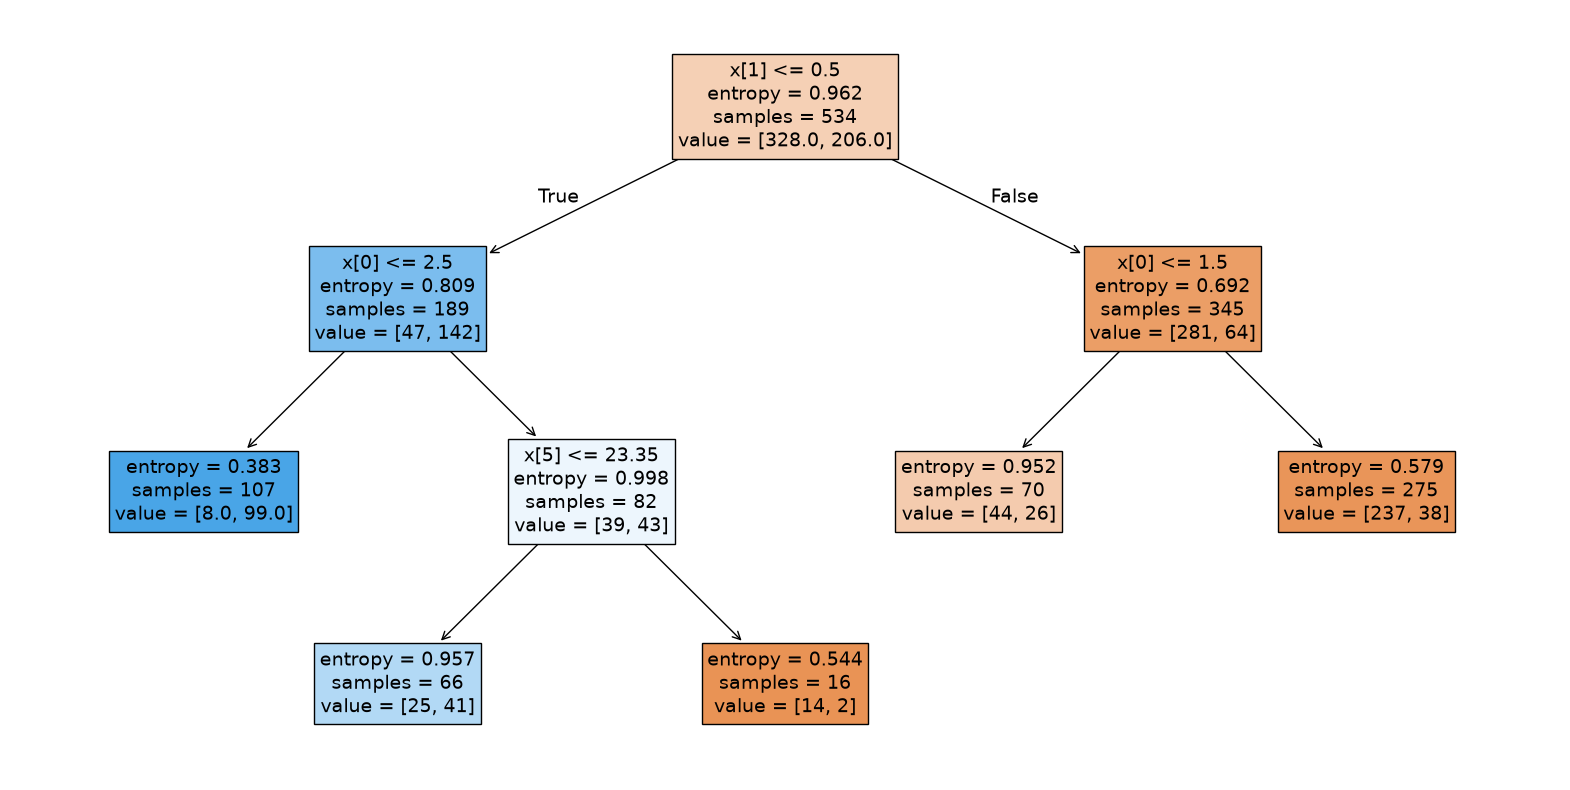

In [32]:
plt.figure(figsize=(20,10))
tree.plot_tree(clf, filled=True, fontsize=14)
plt.show()

### Classification Report

Menampilkan laporan evaluasi lengkap model Decision Tree meliputi Precision, Recall, F1-Score, dan Support untuk setiap kelas.

In [33]:
print(classification_report(labels_test, labels_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       221
           1       0.79      0.66      0.72       136

    accuracy                           0.80       357
   macro avg       0.80      0.78      0.78       357
weighted avg       0.80      0.80      0.80       357

